# 04 · Evaluación final e importancia de variables

1. Se entrena el **modelo ganador** del notebook 03 con todo train.
2. Se evalúa en **test** con el umbral elegido en train.
3. Se mira qué variables pesan más y en qué dirección.
4. Se guardan los archivos que usa `app.py`.

In [1]:
import json

import joblib
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.inspection import PartialDependenceDisplay

from src.data import load_dataset, split_train_test
from src.evaluation import compute_metrics, global_importance, plot_confusion, plot_roc_pr
from src.features import engineer
from src.models import get_models

sns.set_theme(style="whitegrid")
FIG = "../reports/figures/"
pd.set_option("display.width", 140)

winner = json.load(open("../artifacts/winner.json", encoding="utf-8"))
print(winner)

{'modelo': 'RandomForest', 'umbral': 0.5099999999999999}


## 1. Entrenar el ganador con train

In [2]:
X, y = load_dataset()
X = engineer(X)
X_train, X_test, y_train, y_test = split_train_test(X, y)

pipe = get_models()[winner["modelo"]]
pipe.fit(X_train, y_train)
print("Modelo final:", winner["modelo"], "| umbral:", winner["umbral"])

Modelo final: RandomForest | umbral: 0.5099999999999999


## 2. Evaluación en test

In [3]:
proba = pipe.predict_proba(X_test)[:, 1]
m = compute_metrics(y_test, proba, winner["umbral"])
metrics = pd.DataFrame([{"modelo": winner["modelo"], **m}])
print(metrics.round(4).to_string(index=False))

      modelo  roc_auc  pr_auc  recall  precision     f1  threshold
RandomForest    0.649  0.1718  0.4717     0.1504 0.2281       0.51


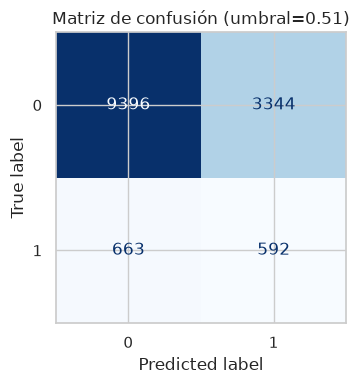

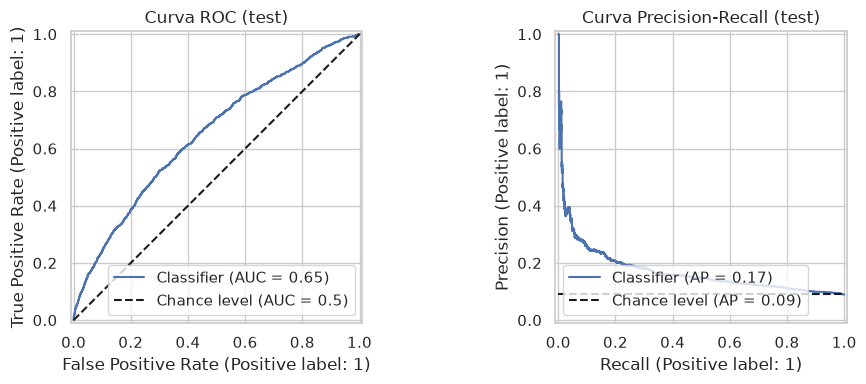

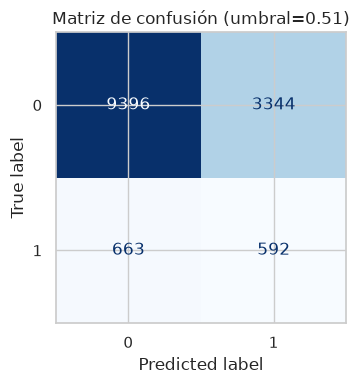

In [4]:
plot_roc_pr(y_test, proba, FIG + "roc_pr_test.png")
plot_confusion(y_test, proba, winner["umbral"], FIG + "confusion_test.png")

### Lectura de la matriz de confusión
Con el umbral 0.51 (elegido en train) el modelo detecta ~47 % de los reingresos (recall 0.47) con
una precisión de ~0.15: de cada 100 alertas, ~15 son reingresos reales, frente a una tasa base del
9 %. Sirve para **priorizar** pacientes, pero da muchas falsas alarmas.

> Como se entrenó con `class_weight`, el puntaje no es una probabilidad real de reingreso; sirve
> para ordenar pacientes y compararlos con el umbral.

## 3. Importancia de variables
Se permuta cada variable y se mide cuánto cae el ROC-AUC.

,feature,importance,std
0,discharge_disposition_id,0.072399,0.003678
1,number_inpatient,0.020913,0.001904
2,age,0.006242,0.002736
3,diag_1_group,0.005832,0.001163
4,diabetesMed,0.005663,0.002639
5,medical_specialty,0.003026,0.000545
6,number_diagnoses,0.002187,0.001967
7,time_in_hospital,0.001865,0.001852
8,admission_type_id,0.001665,0.000400
9,diag_2_group,0.001501,0.000181


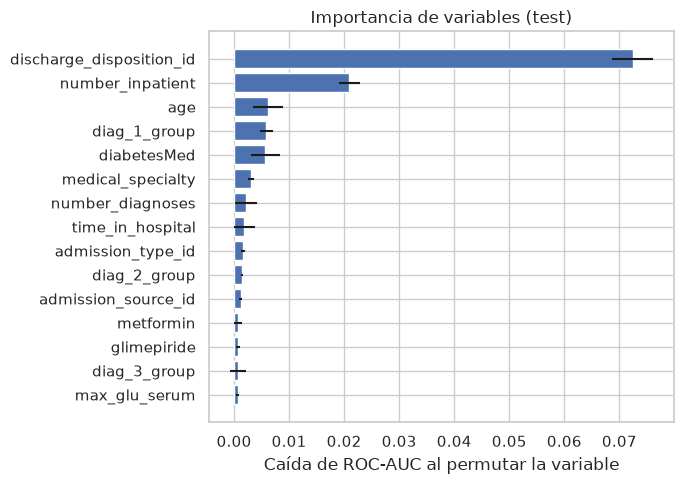

In [5]:
sample = X_test.sample(5000, random_state=42)
imp = global_importance(pipe, sample, y_test.loc[sample.index], n_repeats=3)
top15 = imp.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(top15["feature"], top15["importance"], xerr=top15["std"], color="#4c72b0")
ax.set_xlabel("Caída de ROC-AUC al permutar la variable")
ax.set_title("Importancia de variables (test)")
fig.tight_layout()
fig.savefig(FIG + "importancia_global.png", dpi=130)
imp.head(15)

Para ver **en qué dirección** empuja cada variable se usan gráficas de dependencia parcial.

Variables: ['number_inpatient', 'age', 'number_diagnoses', 'time_in_hospital']


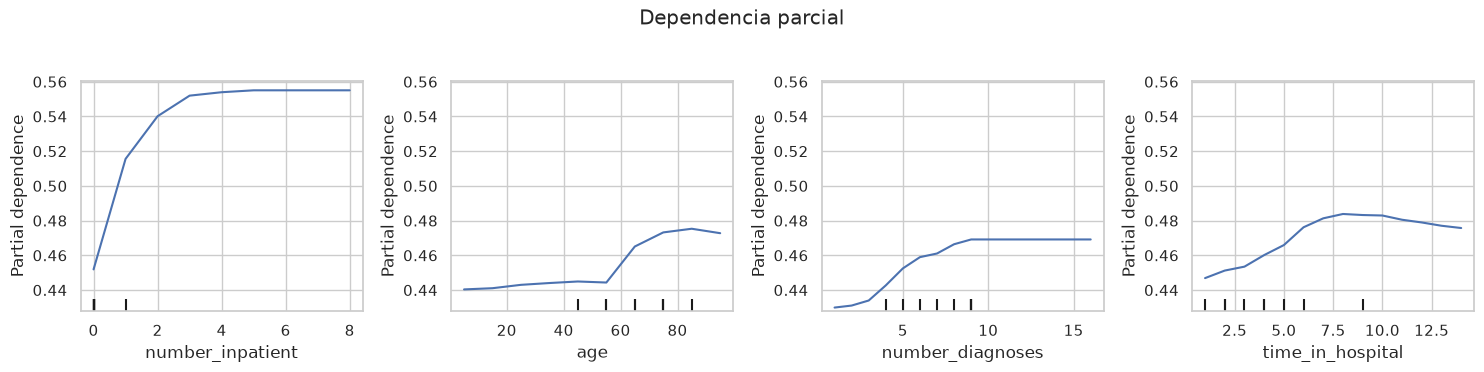

In [6]:
num_top = [f for f in imp["feature"] if pd.api.types.is_numeric_dtype(X_train[f])][:4]
fig, ax = plt.subplots(1, 4, figsize=(15, 3.6))
pd_sample = X_test.sample(3000, random_state=0).astype({c: float for c in num_top})
PartialDependenceDisplay.from_estimator(
    pipe, pd_sample, num_top, ax=ax, kind="average", grid_resolution=15
)
fig.suptitle("Dependencia parcial", y=1.03)
fig.tight_layout()
fig.savefig(FIG + "dependencia_parcial.png", dpi=130, bbox_inches="tight")
print("Variables:", num_top)

## 4. Conclusiones
- **Variables más importantes:** `discharge_disposition_id` (destino al alta) y
  `number_inpatient` (hospitalizaciones previas). Muy por detrás vienen la edad, el diagnóstico
  principal y `diabetesMed`.
- **Hospitalizaciones previas:** el riesgo sube mucho de 0 a 3 ingresos previos y luego se
  estabiliza. Los pacientes que ya han estado hospitalizados son los que más vuelven.
- **Edad:** casi plana hasta los 55-60 años y sube después.
- **Número de diagnósticos:** sube hasta ~9 diagnósticos. **Estancia:** sube hasta ~8 días y luego
  baja un poco.
- Son asociaciones, no causas.

## 5. Guardar archivos para la app

In [7]:
joblib.dump(pipe, "../artifacts/model.joblib")
metrics.to_csv("../artifacts/metrics.csv", index=False)
test_sample = X_test.sample(300, random_state=7).assign(target=y_test)
test_sample.to_csv("../artifacts/test_sample.csv")
print("Guardado: model.joblib, metrics.csv, test_sample.csv")

Guardado: model.joblib, metrics.csv, test_sample.csv
